In [3]:
! python -m pip install gurobipy
! python -m pip install networkx
! python -m pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.3/14.3 MB 106.5 MB/s eta 0:00:00


In [10]:
import gurobipy as gp
from gurobipy import GRB
import networkx as nx

#  Definizione grafo con NetworkX
G = nx.DiGraph()

## Aggiungi nodi
nodes = ["A", "B", "C", "D", "E", "F"]
G.add_nodes_from(nodes)

## Aggiungi archi
edges = [
    ("A","B", 7),  ("A","C", 8),
    ("B","C",-1),  ("B","D", 4), ("B","E", 1), ("B","F", 5),
    ("C","F", 3),
    ("D","F", 1),
    ("E","C",-2), ("E","D", 0),
    ("F","E", 3),
]
G.add_weighted_edges_from(edges, weight="cost")

#  Flussi ai nodi
b = {n: 0 for n in G.nodes}
b.update({
    "A": -1,  # sorgente
    "F":  1,  # destinazione
})

#  Modello Gurobi
m = gp.Model("sp")

# Variabili binarie (archi)
x = m.addVars(G.edges, vtype=GRB.BINARY, name="x")

# Vincoli di bilanciamento
for v in G.nodes:
    inflow  = gp.quicksum(x[i, v] for i in G.predecessors(v))
    outflow = gp.quicksum(x[v, j] for j in G.successors(v))
    m.addConstr(inflow - outflow == b[v], name=f"balance[{v}]")

# O.f.
m.setObjective(gp.quicksum(G[i][j]["cost"] * x[i, j] for (i, j) in G.edges), GRB.MINIMIZE)

# Ottimizza
m.optimize()

#  Risultati
print("\n\n Risultati ottimizzazione:")

archi_in_soluzione = []
if m.status == GRB.OPTIMAL:
    print(f"O.f. = {m.objVal:.6g}")
    print("\nArchi selezionati (x[i,j] = 1):")
    for (i, j) in G.edges:
        if x[i, j].X > 0.5:
            archi_in_soluzione.append((i, j))
            print(f"  {i} -> {j}")




Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (linux64 - "Ubuntu 22.04.4 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 6 rows, 11 columns and 22 nonzeros
Model fingerprint: 0xb5c0909e
Variable types: 0 continuous, 11 integer (11 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [1e+00, 8e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Found heuristic solution: objective 12.0000000
Presolve removed 1 rows and 2 columns
Presolve time: 0.00s
Presolved: 5 rows, 9 columns, 18 nonzeros
Variable types: 0 continuous, 9 integer (9 binary)

Root relaxation: objective 9.000000e+00, 3 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

*    0     0               

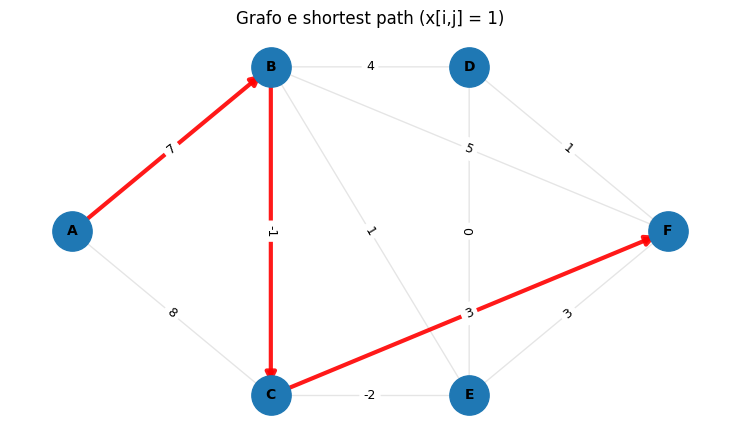

In [11]:
import matplotlib.pyplot as plt

#  Visualizzazione grafo e soluzione

#  Posizioni arbitrarie per i nodi
pos = {
    "A": (0, 2),
    "B": (1.5, 3),
    "C": (1.5, 1),
    "D": (3, 3),
    "E": (3, 1),
    "F": (4.5, 2),
}

plt.figure(figsize=(7.5, 4.5))

# Disegna il grafo
archi_non_in_soluzione = [e for e in G.edges if e not in archi_in_soluzione]
nx.draw_networkx_edges(G, pos, edgelist=archi_non_in_soluzione, width=1.0, alpha=0.1, arrows=True)

# Disegna gli archi propri della soluzione
if archi_in_soluzione:
    nx.draw_networkx_edges(G, pos, edgelist=archi_in_soluzione, width=3.0, alpha=0.9, arrows=True, arrowsize=15, edge_color="red")

# Nodi e label
nx.draw_networkx_nodes(G, pos, node_size=800)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold")

# Etichette dei costi sugli archi
edge_costs = {(u, v): G[u][v]["cost"] for (u, v) in G.edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_costs, font_size=9)

plt.title("Grafo e shortest path (x[i,j] = 1)")
plt.axis("off")
plt.tight_layout()
plt.show()